# Project 2 · Milestone 2 — Notebook 05: Conditional Generation and Parameter Sweeps

**Goal:** run text-conditioned generation on a fixed set of prompts, then test how the main settings change the images.

| Part | What we change | Images |
|---|---|---|
| A. Baseline | nothing: 15 test prompts × 2 seeds, standard settings | 30 |
| B. Guidance scale | 1, 3, 5, 7.5, 10, 15 (4 prompts × 3 seeds) | 72 |
| C. Sampler × steps | DDPM, DDIM, PNDM, Euler, DPM-Solver++ × 10, 20, 30, 50 steps (4 prompts) | 80 |
| D. Noise schedule | the beta schedule (scaled linear, linear, cosine) and Karras sigmas (4 prompts) | 20 |

The text goes in as **our own CLIP embeddings** (`prompt_embeds`), computed with the CLIP text encoder, not as plain text. Every image is saved with its prompt, seed and settings. For every image we record the **CLIP score** (match with the prompt), **time**, **GPU memory** and **color saturation** (very high guidance tends to over-saturate colors). For the guidance sweep we also measure **diversity** across seeds.

Everything is saved in `m2_generation/` and zipped at the end.

**Runtime:** Colab, **T4 GPU**, about 20–25 minutes.

## 1. Install

In [1]:
!pip install -q diffusers transformers accelerate
!pip uninstall -y -q torchao   # Colab's old torchao breaks new diffusers; we don't use it

## 2. Settings

In [2]:
import os, json, time, textwrap, platform
import numpy as np, pandas as pd, torch
from PIL import Image
import matplotlib.pyplot as plt

SEED        = 42
SD_MODEL    = "stable-diffusion-v1-5/stable-diffusion-v1-5"
CLIP_SCORER = "openai/clip-vit-large-patch14"
SIZE        = 512
BASE_STEPS, BASE_GUIDANCE = 30, 7.5            # Milestone 1 baseline settings (PNDM scheduler)

SWEEP_IDS       = [0, 2, 6, 10]                 # dog, soccer jersey "10", five people on bikes, rave
GUIDANCE_SCALES = [1.0, 3.0, 5.0, 7.5, 10.0, 15.0]
GUIDANCE_SEEDS  = [0, 1000, 2000]               # added to 42 + prompt id
SAMPLER_STEPS   = [10, 20, 30, 50]

OUT = "m2_generation"
for sub in ["baseline", "guidance", "sampler", "schedule"]:
    os.makedirs(os.path.join(OUT, "images", sub), exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype  = torch.float16 if device == "cuda" else torch.float32
GPU = torch.cuda.get_device_name(0) if device == "cuda" else "none"
print("device:", device, "| GPU:", GPU)
if device == "cpu":
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU.")

def sync():
    if device == "cuda": torch.cuda.synchronize()

T_START = time.time()

device: cuda | GPU: Tesla T4


## 3. Load our dataset and the Milestone 1 prompts
**No upload needed** (the captions come from our GitHub repo if there is no zip). The baseline prompts are the same 15 **test** captions as Milestone 1.

In [3]:
import os, json, glob, shutil, zipfile, hashlib, urllib.request
import pandas as pd

REPO_RAW = "https://raw.githubusercontent.com/abdul6253/IE7615-group-02-project2/main"
DATA_DIR = "data/flickr30k_subset"
META     = os.path.join(DATA_DIR, "metadata.csv")
os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(META):
    zips = [z for z in glob.glob("*.zip") + glob.glob("*/*.zip")
            if "flickr30k" in z.lower() and zipfile.is_zipfile(z)]
    if zips:
        shutil.unpack_archive(max(zips, key=os.path.getsize), DATA_DIR)
        print("Unzipped", max(zips, key=os.path.getsize))
    else:
        urllib.request.urlretrieve(f"{REPO_RAW}/{META}", META)
        print("Downloaded metadata.csv from our GitHub repo")

df = pd.read_csv(META)
check = hashlib.md5("|".join(sorted(df["filename"] + ":" + df["split"])).encode()).hexdigest()[:10]
print("pairs:", len(df), df["split"].value_counts().to_dict())
print("check code:", check, "(same as Milestone 1)" if check == "477c680542" else "(DIFFERENT from Milestone 1!)")

# The 15 test prompts from Milestone 1 (same captions, same seeds 42 + id)
M1_RESULTS = "baseline_gallery/results.csv"
if not os.path.exists(M1_RESULTS):
    os.makedirs("baseline_gallery", exist_ok=True)
    urllib.request.urlretrieve(f"{REPO_RAW}/{M1_RESULTS}", M1_RESULTS)
m1 = pd.read_csv(M1_RESULTS)
assert set(m1["caption"]) <= set(df.loc[df["split"] == "test", "caption"]), "M1 prompts must come from the test split"
print("Milestone 1 prompts loaded:", len(m1))

Downloaded metadata.csv from our GitHub repo
pairs: 2000 {'train': 1600, 'val': 200, 'test': 200}
check code: 477c680542 (same as Milestone 1)
Milestone 1 prompts loaded: 15


In [4]:
prompts = m1[["id", "domain", "caption"]].copy()
prompts["id"] = prompts["id"].astype(int)
sweep = prompts[prompts["id"].isin(SWEEP_IDS)].reset_index(drop=True)
pd.set_option("display.max_colwidth", 110)
print("Sweep prompts:"); display(sweep)

Sweep prompts:


,id,domain,caption
0,0,animals,A tan dog running through the grass with the background blurry
1,2,sports,A man in a number ten jersey kicks a soccer ball while another team member watches
2,6,city / street,Five people on bikes in traffic with man watching from the side of the road
3,10,indoor,Party goers at a rave dancing by a table with glow sticks on it


## 4. Load Stable Diffusion 1.5 and the CLIP scorer
We keep the built-in **safety checker** on, as in Milestone 1. `clip_embed` turns a caption into the **77 × 768 CLIP embedding** that conditions the U-Net; we pass it to the pipeline as `prompt_embeds`.

In [5]:
from diffusers import (StableDiffusionPipeline, DDPMScheduler, DDIMScheduler, PNDMScheduler,
                       EulerDiscreteScheduler, DPMSolverMultistepScheduler)

pipe = StableDiffusionPipeline.from_pretrained(SD_MODEL, torch_dtype=dtype).to(device)
pipe.set_progress_bar_config(disable=True)
BASE_CFG = pipe.scheduler.config
print("default scheduler:", type(pipe.scheduler).__name__, "| beta schedule:", BASE_CFG["beta_schedule"])

@torch.no_grad()
def clip_embed(texts):
    ids = pipe.tokenizer(texts, padding="max_length", max_length=pipe.tokenizer.model_max_length,
                         truncation=True, return_tensors="pt").input_ids.to(device)
    return pipe.text_encoder(ids)[0]          # (batch, 77, 768)

UNCOND = clip_embed([""])

def run(prompt, seed, steps=BASE_STEPS, guidance=BASE_GUIDANCE, scheduler=None):
    pipe.scheduler = scheduler if scheduler is not None else PNDMScheduler.from_config(BASE_CFG)
    g = torch.Generator(device=device).manual_seed(int(seed))
    cond = clip_embed([prompt])
    if device == "cuda": torch.cuda.reset_peak_memory_stats()
    sync(); t0 = time.time()
    out = pipe(prompt_embeds=cond, negative_prompt_embeds=UNCOND, num_inference_steps=steps,
               guidance_scale=guidance, height=SIZE, width=SIZE, generator=g)
    sync()
    flagged = bool(out.nsfw_content_detected[0]) if out.nsfw_content_detected is not None else False
    mem = round(torch.cuda.max_memory_allocated() / 1e9, 2) if device == "cuda" else 0.0
    return out.images[0], round(time.time() - t0, 2), mem, flagged

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

default scheduler: PNDMScheduler | beta schedule: scaled_linear


In [6]:
from transformers import CLIPModel, CLIPProcessor

clip_proc = CLIPProcessor.from_pretrained(CLIP_SCORER)
clip = CLIPModel.from_pretrained(CLIP_SCORER).to(device=device, dtype=dtype).eval()

@torch.no_grad()
def score_text(texts):
    inp = clip_proc.tokenizer(texts, padding="max_length", max_length=77, truncation=True, return_tensors="pt").to(device)
    e = clip.text_projection(clip.text_model(**inp).pooler_output)
    return torch.nn.functional.normalize(e.float(), dim=-1)

@torch.no_grad()
def score_image(images):
    pix = clip_proc(images=images, return_tensors="pt")["pixel_values"].to(device, dtype)
    e = clip.visual_projection(clip.vision_model(pixel_values=pix).pooler_output)
    return torch.nn.functional.normalize(e.float(), dim=-1)

def clip_score(image, text):
    # CLIP score = 100 x cosine similarity between the image and its caption (higher = better match)
    return round(100 * float((score_image([image]) * score_text([text])).sum()), 2)

def pairwise_similarity(images):
    # mean CLIP similarity between different images (lower = more variety)
    e = score_image(images)
    s = e @ e.T
    return round(100 * float(s[~torch.eye(len(images), dtype=bool, device=s.device)].mean()), 2)

print("CLIP scorer loaded:", CLIP_SCORER)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

CLIP scorer loaded: openai/clip-vit-large-patch14


In [7]:
def saturation(img):
    # mean color saturation, 0-100 (HSV S channel)
    return round(float(np.asarray(img.convert("HSV"))[..., 1].mean() / 255 * 100), 1)

ROWS = []
def record(img, part, sub, fname, **info):
    img.save(os.path.join(OUT, "images", sub, fname))
    info = {k: (int(v) if isinstance(v, np.integer) else v) for k, v in info.items()}
    ROWS.append({"part": part, **info, "clip_score": clip_score(img, info["prompt"]),
                 "saturation": saturation(img), "file": f"images/{sub}/{fname}"})

# warm-up run so the first timed image does not include CUDA start-up
_ = run("a photo of a dog", 0, steps=5)
print("ready")

ready


## 5. Part A: baseline conditional generation
15 test prompts × 2 seeds (`42 + id` as in Milestone 1, and `1042 + id`), PNDM, 30 steps, guidance 7.5. The first seed should give the **same images as Milestone 1**, which shows the conditioning through our own embeddings is identical to plain text input.

In [8]:
for _, r in prompts.iterrows():
    for s in [SEED + r["id"], SEED + 1000 + r["id"]]:
        img, secs, mem, fl = run(r["caption"], s)
        record(img, "A_baseline", "baseline", f"base_{r['id']:02d}_seed{s}.png", prompt_id=r["id"], prompt=r["caption"],
               seed=s, sampler="PNDM", steps=BASE_STEPS, guidance=BASE_GUIDANCE, schedule="scaled_linear",
               seconds=secs, peak_gpu_gb=mem, safety_flagged=fl)
    print(f"#{r['id']:2d} done  {r['caption'][:70]}")

res = pd.DataFrame(ROWS)
base = res[res.part == "A_baseline"]
print(f"\nBaseline: mean CLIP score {base.clip_score.mean():.2f} | {base.seconds.mean():.2f}s per image | "
      f"peak GPU {base.peak_gpu_gb.max()} GB | flagged {int(base.safety_flagged.sum())}")

# same as Milestone 1? (seed 42 + id images)
diffs = []
for _, r in prompts.iterrows():
    try:
        m1_file = f"baseline_gallery/generated/gen_{r['id']:02d}.png"
        if not os.path.exists(m1_file):
            os.makedirs("baseline_gallery/generated", exist_ok=True)
            urllib.request.urlretrieve(f"{REPO_RAW}/{m1_file}", m1_file)
        a = np.asarray(Image.open(m1_file).convert("RGB"), dtype=np.float32)
        b = np.asarray(Image.open(os.path.join(OUT, "images", "baseline", f"base_{r['id']:02d}_seed{SEED + r['id']}.png")).convert("RGB"), dtype=np.float32)
        diffs.append(float(np.abs(a - b).mean()))
    except Exception as e:
        print("could not compare with Milestone 1:", e); break
M1_DIFF = round(float(np.mean(diffs)), 3) if diffs else None
print("Mean pixel difference vs Milestone 1 images (0-255):", M1_DIFF)

# 0 done  A tan dog running through the grass with the background blurry
# 1 done  A dog with golden fur is chest deep in water
# 2 done  A man in a number ten jersey kicks a soccer ball while another team me
# 3 done  A person jumping their bike in the woods in front of trees with no lea
# 4 done  Men and women in bathing suits are standing at poolside while another 
# 5 done  Boy heads into water big tents and hills in background in rural area
# 6 done  Five people on bikes in traffic with man watching from the side of the
# 7 done  People are walking on the slippery road in winter and there are two do
# 8 done  A couple and their child pose for a picture in front of a Christmas tr
# 9 done  Three dogs who are brown white and black ( respectively ) play with on
#10 done  Party goers at a rave dancing by a table with glow sticks on it
#11 done  Three women and a man sitting at a table with a large pitcher of beer
#12 done  A group of people ride a blue roller coaster on its way down f

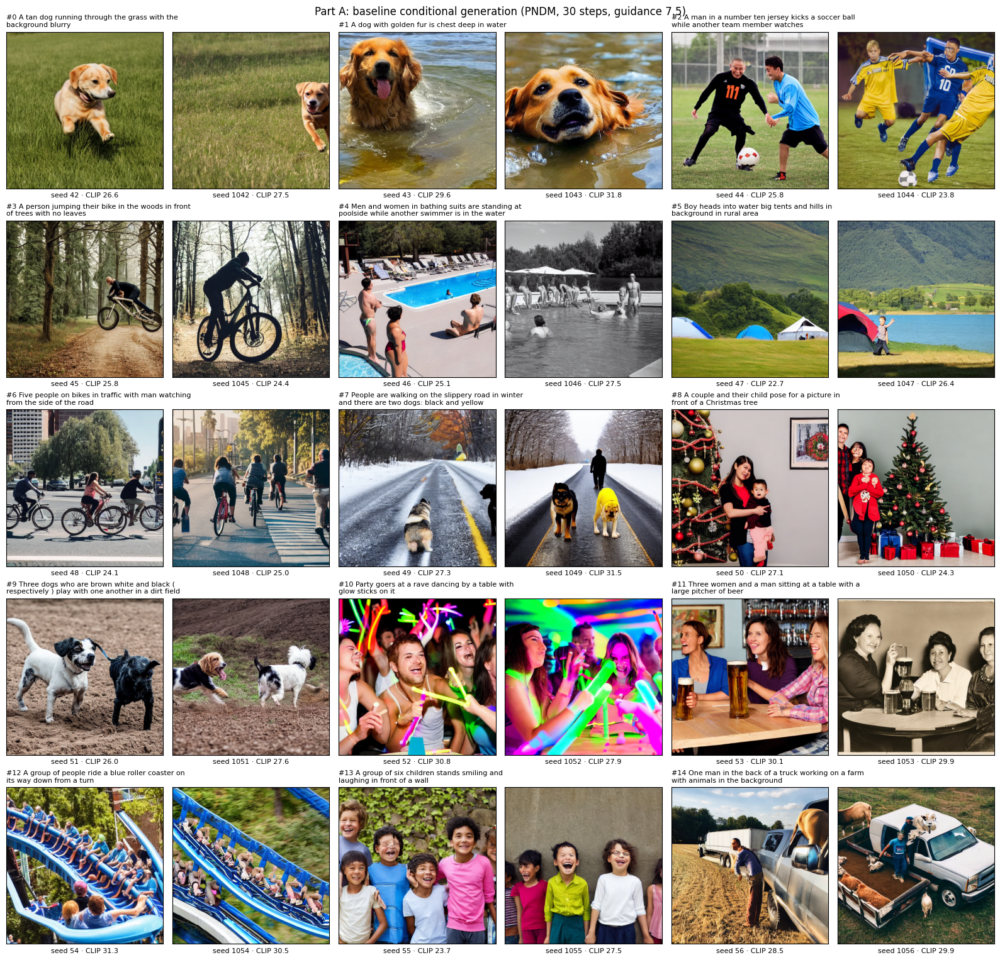

In [9]:
# Baseline gallery: 3 prompts per row, 2 seeds each
ids = prompts["id"].tolist()
fig, ax = plt.subplots(5, 6, figsize=(16, 15.5))
for k, i in enumerate(ids):
    rows_i = base[base.prompt_id == i].sort_values("seed")
    for j, (_, r) in enumerate(rows_i.iterrows()):
        a = ax[k // 3, (k % 3) * 2 + j]
        a.imshow(Image.open(os.path.join(OUT, r["file"]))); a.set_xticks([]); a.set_yticks([])
        a.set_xlabel(f"seed {r['seed']} · CLIP {r['clip_score']:.1f}", fontsize=8)
        if j == 0:
            a.set_title(textwrap.fill(f"#{i} {r['prompt']}", 52), fontsize=8, loc="left")
plt.suptitle("Part A: baseline conditional generation (PNDM, 30 steps, guidance 7.5)", fontsize=12)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "A_baseline_gallery.png"), dpi=80, bbox_inches="tight"); plt.show()

## 6. Part B: guidance scale sweep
**Classifier-free guidance** sets how strongly the image follows the text: `noise = uncond + scale × (cond − uncond)`. Scale 1 means no extra push toward the prompt. Same 4 prompts and 3 seeds at every scale, so only the scale changes.

In [10]:
for _, r in sweep.iterrows():
    for gs in GUIDANCE_SCALES:
        for off in GUIDANCE_SEEDS:
            s = SEED + off + r["id"]
            img, secs, mem, fl = run(r["caption"], s, guidance=gs)
            record(img, "B_guidance", "guidance", f"gs{gs:g}_{r['id']:02d}_seed{s}.png", prompt_id=r["id"],
                   prompt=r["caption"], seed=s, sampler="PNDM", steps=BASE_STEPS, guidance=gs,
                   schedule="scaled_linear", seconds=secs, peak_gpu_gb=mem, safety_flagged=fl)
    print(f"#{r['id']:2d} done")

res = pd.DataFrame(ROWS)
gdf = res[res.part == "B_guidance"]
div_rows = []
for (pid, gs), grp in gdf.groupby(["prompt_id", "guidance"]):
    imgs = [Image.open(os.path.join(OUT, f)).convert("RGB") for f in grp["file"]]
    div_rows.append({"prompt_id": pid, "guidance": gs, "seed_similarity": pairwise_similarity(imgs)})
div = pd.DataFrame(div_rows)
g_table = (gdf.groupby("guidance")[["clip_score", "saturation", "seconds", "peak_gpu_gb"]].mean()
           .join(div.groupby("guidance")["seed_similarity"].mean()).round(2).reset_index())
display(g_table)

# 0 done
# 2 done
# 6 done
#10 done


,guidance,clip_score,saturation,seconds,peak_gpu_gb,seed_similarity
0,1.0,20.78,30.68,3.43,4.29,68.24
1,3.0,24.83,34.22,5.70,4.29,81.32
2,5.0,25.82,39.89,5.68,4.29,84.84
3,7.5,25.97,46.39,5.64,4.29,86.62
4,10.0,25.64,50.77,5.64,4.29,87.30
5,15.0,25.87,57.51,5.65,4.29,89.64


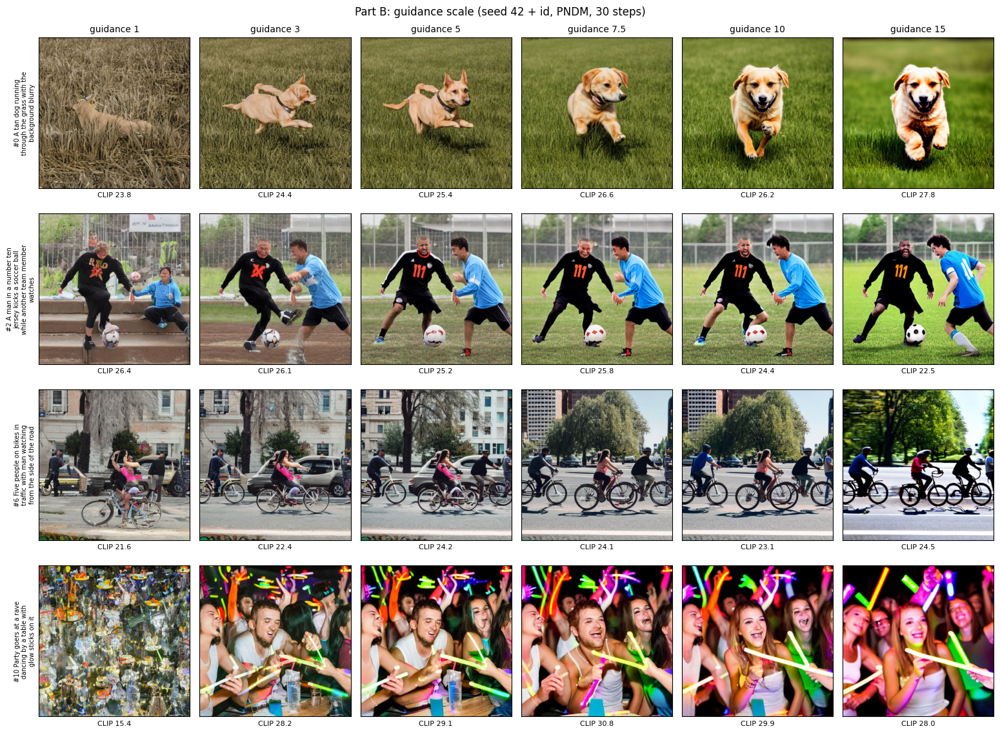

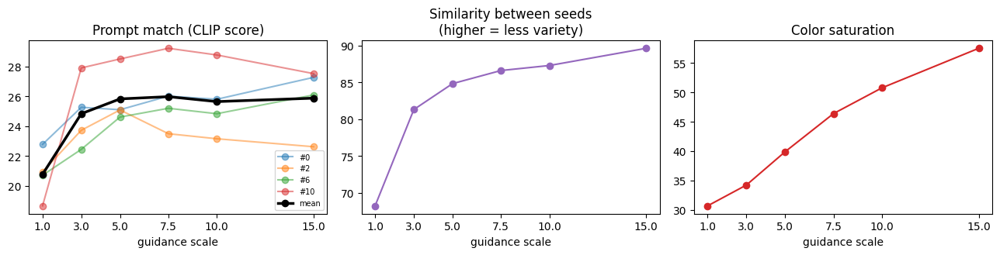

In [11]:
fig, ax = plt.subplots(len(SWEEP_IDS), len(GUIDANCE_SCALES), figsize=(2.6 * len(GUIDANCE_SCALES), 2.9 * len(SWEEP_IDS)))
for rr, (_, r) in enumerate(sweep.iterrows()):
    for cc, gs in enumerate(GUIDANCE_SCALES):
        row = gdf[(gdf.prompt_id == r["id"]) & (gdf.guidance == gs) & (gdf.seed == SEED + r["id"])].iloc[0]
        a = ax[rr, cc]; a.imshow(Image.open(os.path.join(OUT, row["file"]))); a.set_xticks([]); a.set_yticks([])
        a.set_xlabel(f"CLIP {row['clip_score']:.1f}", fontsize=8)
        if rr == 0: a.set_title(f"guidance {gs:g}", fontsize=10)
        if cc == 0: a.set_ylabel(textwrap.fill(f"#{r['id']} {r['caption']}", 26), fontsize=7)
plt.suptitle("Part B: guidance scale (seed 42 + id, PNDM, 30 steps)", fontsize=12)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "B_guidance_grid.png"), dpi=80, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for pid, grp in gdf.groupby("prompt_id"):
    m = grp.groupby("guidance")["clip_score"].mean()
    ax[0].plot(m.index, m.values, "o-", alpha=0.5, label=f"#{pid}")
ax[0].plot(g_table["guidance"], g_table["clip_score"], "k-o", lw=2.5, label="mean")
ax[0].set_title("Prompt match (CLIP score)"); ax[0].legend(fontsize=7)
ax[1].plot(g_table["guidance"], g_table["seed_similarity"], "o-", color="tab:purple")
ax[1].set_title("Similarity between seeds\n(higher = less variety)")
ax[2].plot(g_table["guidance"], g_table["saturation"], "o-", color="tab:red")
ax[2].set_title("Color saturation")
for a in ax: a.set_xlabel("guidance scale"); a.set_xticks(GUIDANCE_SCALES)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "B_guidance_metrics.png"), dpi=120, bbox_inches="tight"); plt.show()

## 7. Part C: sampler and number of steps
The **sampler** (scheduler) decides how the noise is removed. **DDPM** is the original stochastic method and needs many steps; **DDIM** is its fast, deterministic version; **PNDM** is Stable Diffusion's default; **Euler** and **DPM-Solver++** are newer ODE solvers. Fewer steps means faster images; the question is how much quality is lost. Guidance stays 7.5, seed `42 + id`.

In [12]:
SAMPLERS = {
    "DDPM":         lambda: DDPMScheduler.from_config(BASE_CFG),
    "DDIM":         lambda: DDIMScheduler.from_config(BASE_CFG),
    "PNDM":         lambda: PNDMScheduler.from_config(BASE_CFG),
    "Euler":        lambda: EulerDiscreteScheduler.from_config(BASE_CFG),
    "DPM-Solver++": lambda: DPMSolverMultistepScheduler.from_config(BASE_CFG),
}
for name, make in SAMPLERS.items():
    for n in SAMPLER_STEPS:
        for _, r in sweep.iterrows():
            s = SEED + r["id"]
            img, secs, mem, fl = run(r["caption"], s, steps=n, scheduler=make())
            record(img, "C_sampler", "sampler", f"{name.replace('+', 'p')}_{n}_{r['id']:02d}.png", prompt_id=r["id"],
                   prompt=r["caption"], seed=s, sampler=name, steps=n, guidance=BASE_GUIDANCE,
                   schedule="scaled_linear", seconds=secs, peak_gpu_gb=mem, safety_flagged=fl)
    print(name, "done")

res = pd.DataFrame(ROWS)
cdf = res[res.part == "C_sampler"]
c_table = cdf.pivot_table(index="sampler", columns="steps", values="clip_score", aggfunc="mean").round(2)
t_table = cdf.pivot_table(index="sampler", columns="steps", values="seconds", aggfunc="mean").round(2)
c_table, t_table = c_table.reindex(list(SAMPLERS)), t_table.reindex(list(SAMPLERS))
print("Mean CLIP score:"); display(c_table)
print("Seconds per image:"); display(t_table)

DDPM done
DDIM done
PNDM done
Euler done
DPM-Solver++ done
Mean CLIP score:


steps,10,20,30,50
sampler,,,,
DDPM,27.38,25.59,25.50,25.95
DDIM,26.12,26.08,25.82,26.82
PNDM,26.53,26.59,26.84,26.22
Euler,26.78,26.44,26.66,26.24
DPM-Solver++,26.33,25.86,26.32,26.11


Seconds per image:


steps,10,20,30,50
sampler,,,,
DDPM,1.98,3.83,5.60,8.91
DDIM,1.99,3.75,5.53,9.02
PNDM,2.16,3.90,5.65,9.14
Euler,1.98,3.73,5.50,9.04
DPM-Solver++,2.01,3.75,5.50,9.06


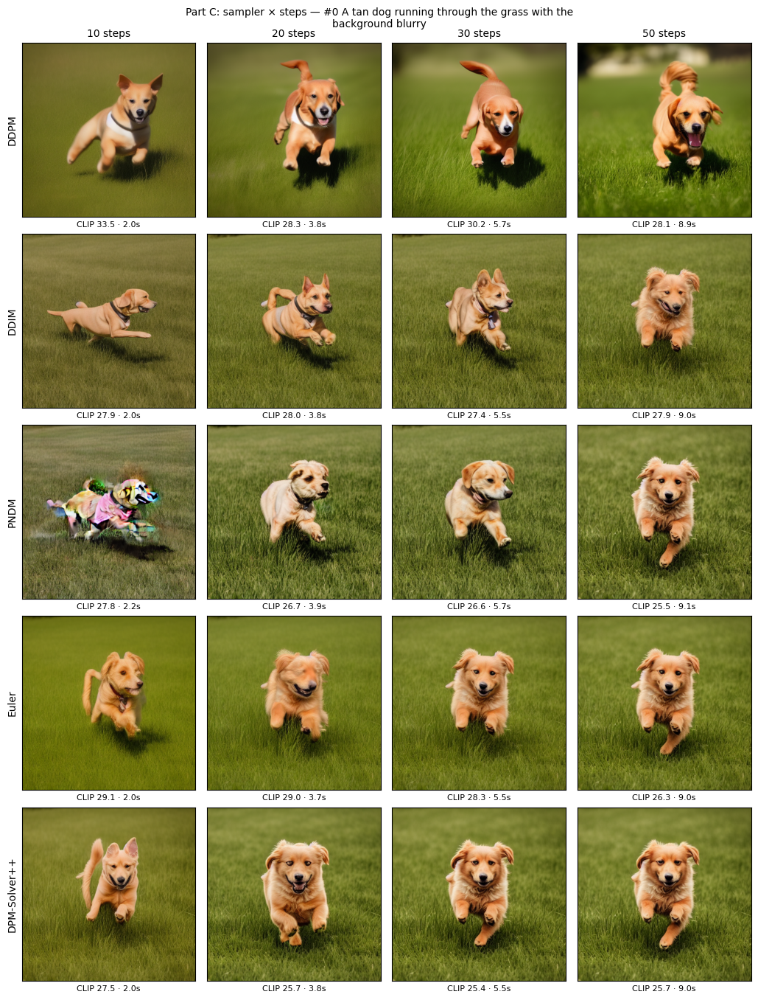

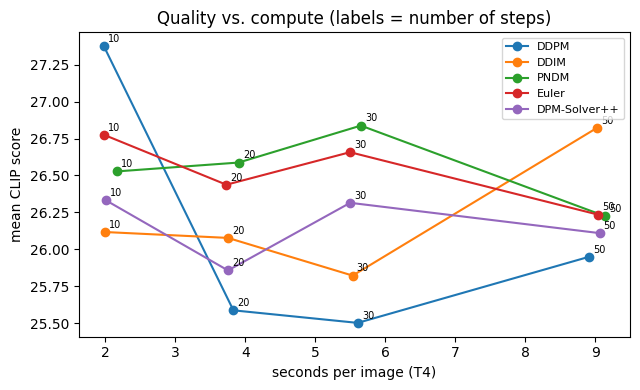

In [13]:
for _, r in sweep.iterrows():
    fig, ax = plt.subplots(len(SAMPLERS), len(SAMPLER_STEPS), figsize=(2.6 * len(SAMPLER_STEPS), 2.75 * len(SAMPLERS)))
    for rr, name in enumerate(SAMPLERS):
        for cc, n in enumerate(SAMPLER_STEPS):
            row = cdf[(cdf.prompt_id == r["id"]) & (cdf.sampler == name) & (cdf.steps == n)].iloc[0]
            a = ax[rr, cc]; a.imshow(Image.open(os.path.join(OUT, row["file"]))); a.set_xticks([]); a.set_yticks([])
            a.set_xlabel(f"CLIP {row['clip_score']:.1f} · {row['seconds']:.1f}s", fontsize=8)
            if rr == 0: a.set_title(f"{n} steps", fontsize=10)
            if cc == 0: a.set_ylabel(name, fontsize=10)
    plt.suptitle(textwrap.fill(f"Part C: sampler × steps — #{r['id']} {r['caption']}", 80), fontsize=10)
    plt.tight_layout(); plt.savefig(os.path.join(OUT, f"C_sampler_grid_{r['id']:02d}.png"), dpi=80, bbox_inches="tight")
    plt.show() if r["id"] == SWEEP_IDS[0] else plt.close()

fig, ax = plt.subplots(figsize=(6.5, 4))
for name in SAMPLERS:
    m = cdf[cdf.sampler == name].groupby("steps")[["seconds", "clip_score"]].mean()
    ax.plot(m["seconds"], m["clip_score"], "o-", label=name)
    for n, row in m.iterrows():
        ax.annotate(str(n), (row["seconds"], row["clip_score"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("seconds per image (T4)"); ax.set_ylabel("mean CLIP score")
ax.set_title("Quality vs. compute (labels = number of steps)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "C_quality_vs_compute.png"), dpi=120, bbox_inches="tight"); plt.show()

## 8. Part D: noise schedule
The **noise schedule** (beta schedule) says how much noise is added at each of the 1,000 training steps. Stable Diffusion was trained with **scaled linear**. We sample with DDIM (30 steps) using **linear** and **cosine** schedules too: this shows what happens when the sampler's schedule does not match training. We also test **Karras sigmas**, a different spacing of noise levels at sampling time, with DPM-Solver++ at 20 steps.

DDIM · scaled linear (trained) done
DDIM · linear done
DDIM · cosine done
DPM++ · default sigmas done
DPM++ · Karras sigmas done


,schedule,clip_score,saturation,seconds
0,DDIM · scaled linear (trained),25.82,41.70,5.53
1,DDIM · linear,25.97,54.40,5.74
2,DDIM · cosine,25.34,45.10,5.38
3,DPM++ · default sigmas,25.86,45.00,3.65
4,DPM++ · Karras sigmas,25.62,43.92,3.73


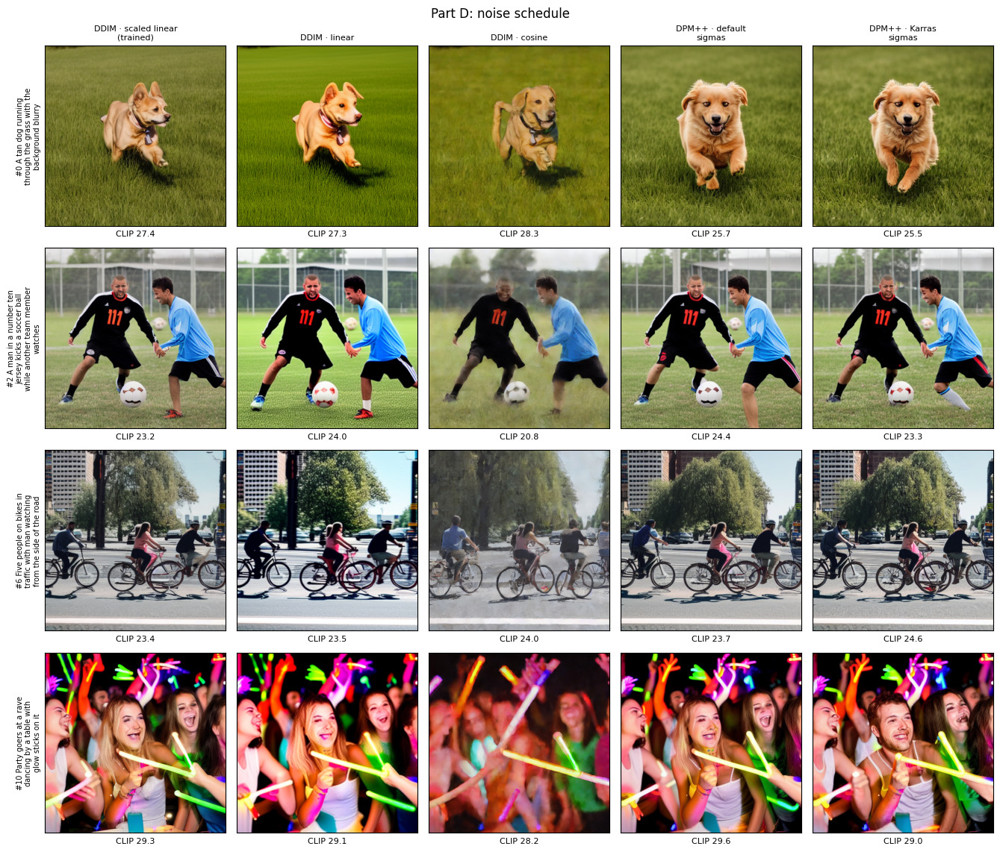

In [14]:
SCHEDULES = {
    "DDIM · scaled linear (trained)": (lambda: DDIMScheduler.from_config(BASE_CFG), 30),
    "DDIM · linear":                  (lambda: DDIMScheduler.from_config(BASE_CFG, beta_schedule="linear"), 30),
    "DDIM · cosine":                  (lambda: DDIMScheduler.from_config(BASE_CFG, beta_schedule="squaredcos_cap_v2"), 30),
    "DPM++ · default sigmas":         (lambda: DPMSolverMultistepScheduler.from_config(BASE_CFG), 20),
    "DPM++ · Karras sigmas":          (lambda: DPMSolverMultistepScheduler.from_config(BASE_CFG, use_karras_sigmas=True), 20),
}
for k, (label, (make, n)) in enumerate(SCHEDULES.items()):
    for _, r in sweep.iterrows():
        s = SEED + r["id"]
        img, secs, mem, fl = run(r["caption"], s, steps=n, scheduler=make())
        record(img, "D_schedule", "schedule", f"sched{k}_{r['id']:02d}.png", prompt_id=r["id"], prompt=r["caption"],
               seed=s, sampler=label.split(" · ")[0], steps=n, guidance=BASE_GUIDANCE, schedule=label,
               seconds=secs, peak_gpu_gb=mem, safety_flagged=fl)
    print(label, "done")

res = pd.DataFrame(ROWS)
ddf = res[res.part == "D_schedule"]
d_table = ddf.groupby("schedule", sort=False)[["clip_score", "saturation", "seconds"]].mean().round(2).reset_index()
display(d_table)

fig, ax = plt.subplots(len(SWEEP_IDS), len(SCHEDULES), figsize=(2.7 * len(SCHEDULES), 2.9 * len(SWEEP_IDS)))
for rr, (_, r) in enumerate(sweep.iterrows()):
    for cc, label in enumerate(SCHEDULES):
        row = ddf[(ddf.prompt_id == r["id"]) & (ddf.schedule == label)].iloc[0]
        a = ax[rr, cc]; a.imshow(Image.open(os.path.join(OUT, row["file"]))); a.set_xticks([]); a.set_yticks([])
        a.set_xlabel(f"CLIP {row['clip_score']:.1f}", fontsize=8)
        if rr == 0: a.set_title(textwrap.fill(label, 20), fontsize=8)
        if cc == 0: a.set_ylabel(textwrap.fill(f"#{r['id']} {r['caption']}", 26), fontsize=7)
plt.suptitle("Part D: noise schedule", fontsize=12)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "D_schedule_grid.png"), dpi=80, bbox_inches="tight"); plt.show()

## 9. Save all results and download
`results.csv` has one row per image: prompt, seed, sampler, steps, guidance, schedule, time, GPU memory, CLIP score, saturation and file. `summary.json` has the summary tables.

In [15]:
import diffusers, transformers
res = pd.DataFrame(ROWS)
res.to_csv(os.path.join(OUT, "results.csv"), index=False)
div.to_csv(os.path.join(OUT, "guidance_diversity.csv"), index=False)
assert res["file"].map(lambda f: os.path.exists(os.path.join(OUT, f))).all()

summary = {
    "gpu": GPU, "python": platform.python_version(), "torch": torch.__version__,
    "diffusers": diffusers.__version__, "transformers": transformers.__version__,
    "sd_model": SD_MODEL, "n_images": len(res), "images_per_part": {k: int(v) for k, v in res["part"].value_counts().items()},
    "safety_flagged": int(res["safety_flagged"].sum()), "peak_gpu_gb": float(res["peak_gpu_gb"].max()),
    "A_baseline": {"mean_clip": round(base.clip_score.mean(), 2), "mean_seconds": round(base.seconds.mean(), 2),
                   "mean_pixel_diff_vs_milestone1": M1_DIFF,
                   "per_prompt": {int(k): float(v) for k, v in base.groupby("prompt_id")["clip_score"].mean().round(2).items()}},
    "B_guidance": g_table.to_dict(orient="records"),
    "C_sampler_clip": {k: {int(n): float(x) for n, x in v.items()} for k, v in c_table.to_dict(orient="index").items()},
    "C_sampler_seconds": {k: {int(n): float(x) for n, x in v.items()} for k, v in t_table.to_dict(orient="index").items()},
    "D_schedule": d_table.to_dict(orient="records"),
    "total_minutes": round((time.time() - T_START) / 60, 1),
}
with open(os.path.join(OUT, "summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=1, default=str)[:3000])

shutil.make_archive("m2_generation", "zip", OUT)
print("Created m2_generation.zip")
try:
    from google.colab import files
    files.download("m2_generation.zip")
except Exception:
    print("Download m2_generation.zip from the file panel on the left.")

{
 "gpu": "Tesla T4",
 "python": "3.13.16",
 "torch": "2.11.0+cu130",
 "diffusers": "0.42.1",
 "transformers": "5.22.0",
 "sd_model": "stable-diffusion-v1-5/stable-diffusion-v1-5",
 "n_images": 202,
 "images_per_part": {
  "C_sampler": 80,
  "B_guidance": 72,
  "A_baseline": 30,
  "D_schedule": 20
 },
 "safety_flagged": 0,
 "peak_gpu_gb": 4.29,
 "A_baseline": {
  "mean_clip": 27.33,
  "mean_seconds": 5.01,
  "mean_pixel_diff_vs_milestone1": 0.0,
  "per_prompt": {
   "0": 27.08,
   "1": 30.72,
   "2": 24.78,
   "3": 25.08,
   "4": 26.28,
   "5": 24.52,
   "6": 24.56,
   "7": 29.38,
   "8": 25.69,
   "9": 26.82,
   "10": 29.34,
   "11": 30.02,
   "12": 30.88,
   "13": 25.59,
   "14": 29.2
  }
 },
 "B_guidance": [
  {
   "guidance": 1.0,
   "clip_score": 20.78,
   "saturation": 30.68,
   "seconds": 3.43,
   "peak_gpu_gb": 4.29,
   "seed_similarity": 68.24
  },
  {
   "guidance": 3.0,
   "clip_score": 24.83,
   "saturation": 34.22,
   "seconds": 5.7,
   "peak_gpu_gb": 4.29,
   "seed_simila

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>